# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import PlanesNetDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/planesnet/",
    "csv_file": "./data/planesnet/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = PlanesNetDataset(dataset_config)

## Show images from the dataset

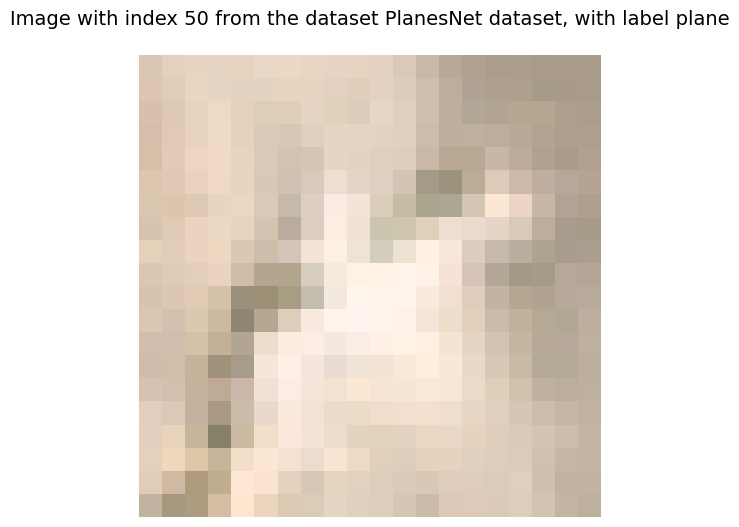

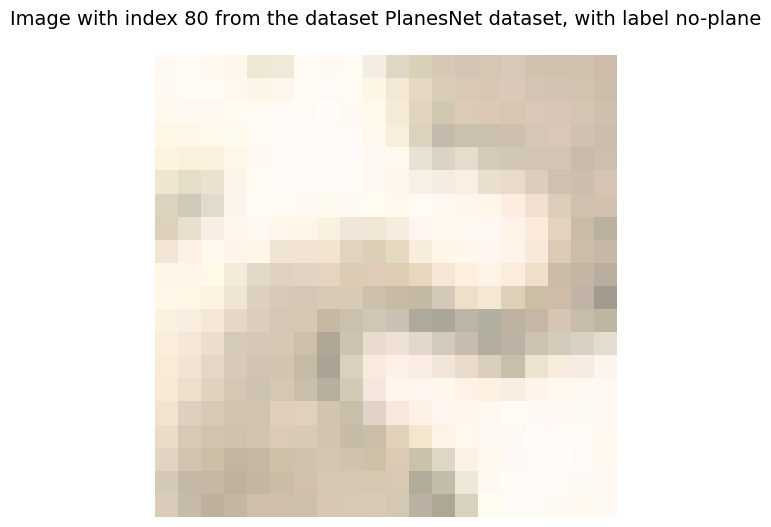

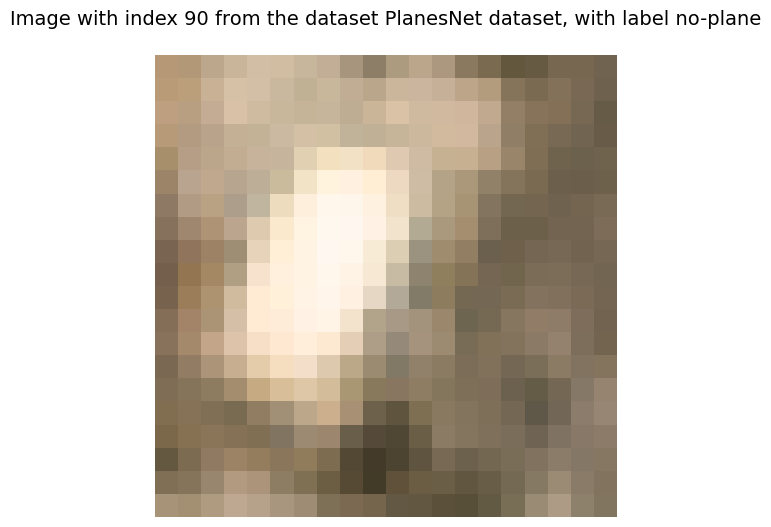

In [15]:
fig1 = dataset.show_image(50)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(90)

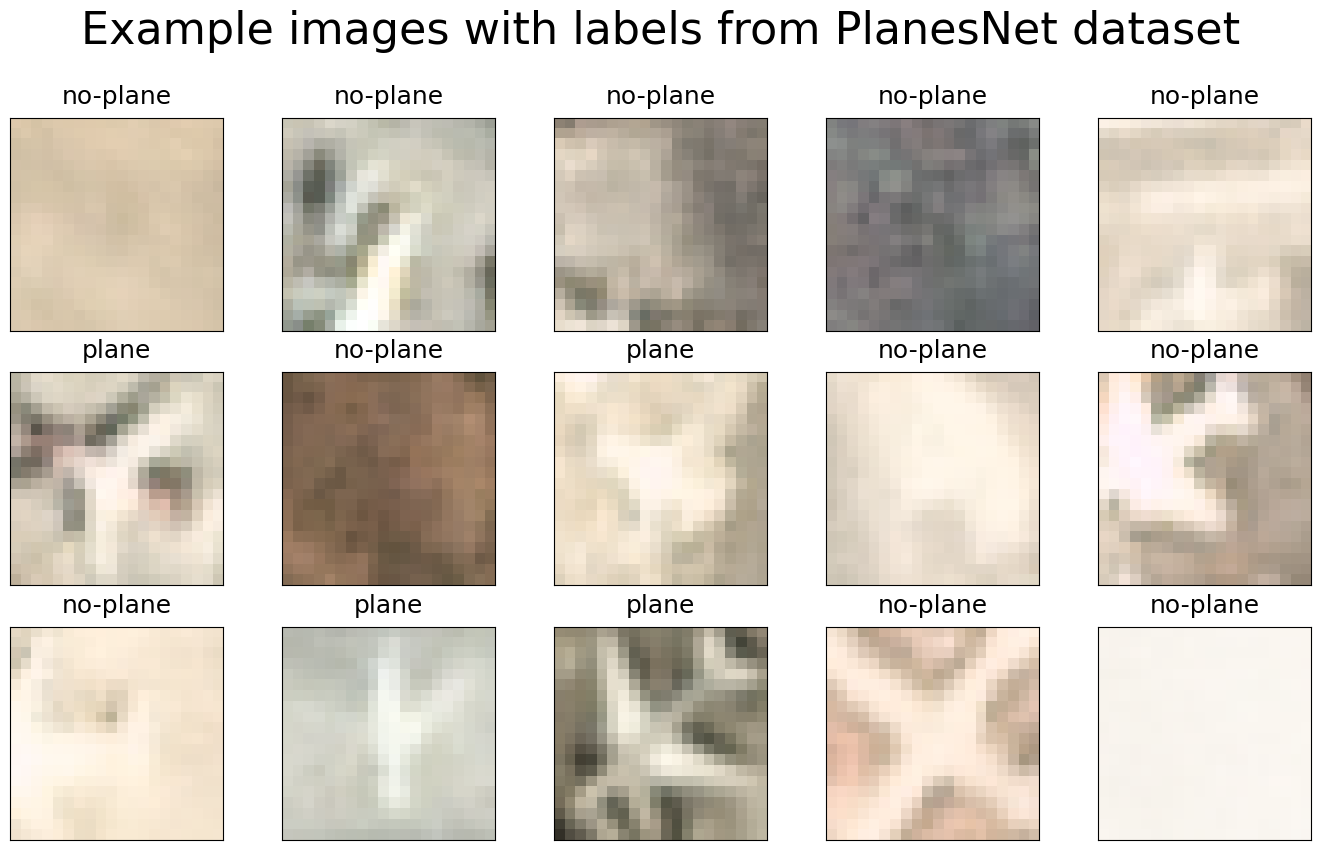

In [14]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [22]:
dataset.show_samples()

,File name,Label
0,images/0__20160414_203124_0c68__-117.720811327...,no-ship
1,images/0__20170602_174848_1029__-118.405069404...,no-ship
2,images/0__20160831_174606_0e1f__-118.030118089...,no-ship
3,images/1__20161018_193327_0c45__-122.3876445_3...,ship
4,images/0__20160830_220133_0c24__-118.405834508...,no-ship
5,images/0__20161214_174938_0e26__-118.459916787...,no-ship
6,images/0__20170511_180609_1041__-122.158191331...,no-ship
7,images/0__20150813_225644_0b09__-118.396243840...,no-ship
8,images/0__20150917_164233_0c03__-118.417523571...,no-ship
9,images/1__20160829_195800_0c72__-122.389857562...,ship


In [23]:
dataset.data_distribution_table()

,Label,Count
0,no-plane,19269
1,plane,6331


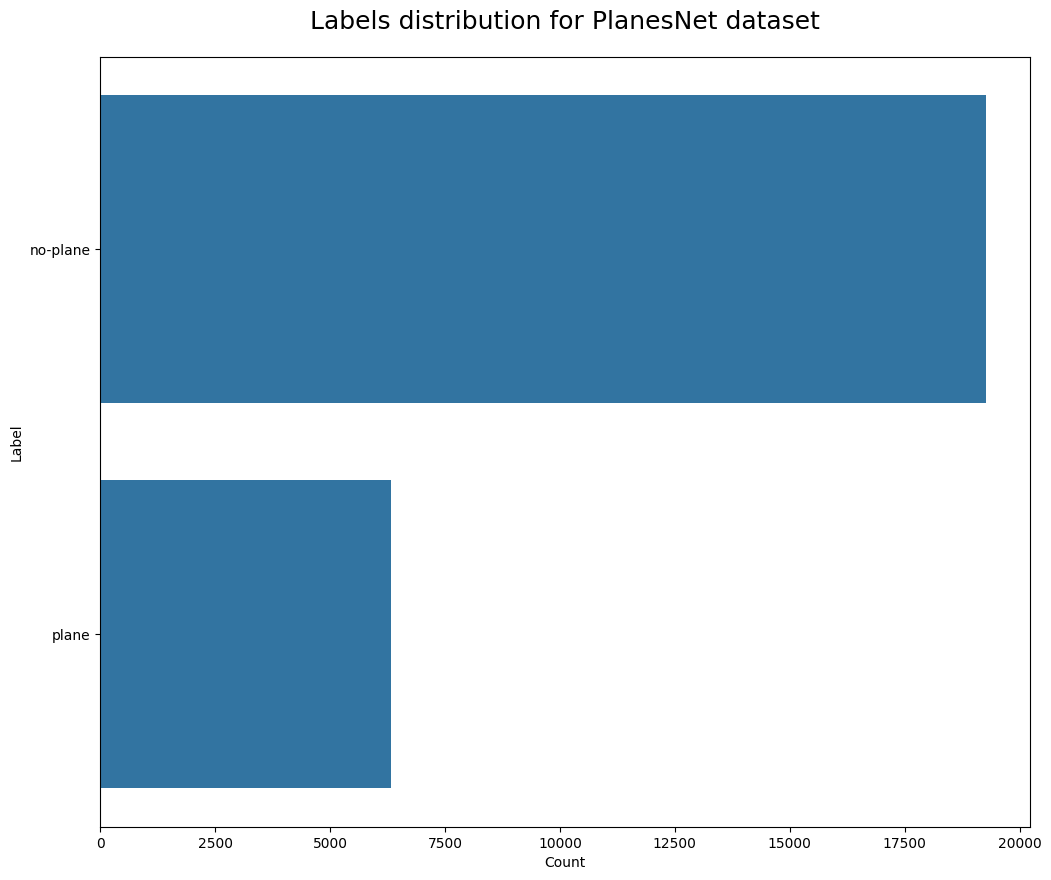

In [24]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/planesnet/",
    "csv_file": "./data/planesnet/train.csv",
}

train_dataset = PlanesNetDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/planesnet/",
    "csv_file": "./data/planesnet/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = PlanesNetDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(25600, 3200)

## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/PlanesNet/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-14 07:07:30,581 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-14 07:07:30,824 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-14 07:07:30,884 INFO Starting training.
training: 100%|██████████| 800/800 [05:54<00:00,  2.26it/s]
2025-05-14 07:13:25,331 INFO epoch: 1, time: 355, loss:  0.10105
testing on train set: 100%|██████████| 800/800 [02:41<00:00,  4.95it/s]
2025-05-14 07:16:09,861 INFO Accuracy:0.963984375, Precision Micro:0.963984375, Precision Macro:0.9367079120564423, Precision Weighted:0.968392494348034, Precision per Class:[0.99940117 0.87401466], Recall Micro:0.963984375, Recall Macro:0.975492253228098, Recall Weighted:0.9639843750000001, Recall per Class:[0.95272199 0.99826252], F1_score Micro:0.9639843749999994, F1_score Macro:0.9537597036897233, F1_score Weighted:0.9647488046543647, F1_score per Class:[0.97550348 0.93201593]
testing on validation set: 100%|██████████| 100/100 [00:20<00:00,  4.96it/s]
2025-05-14 07:16:30,039 INFO Accuracy:0.9603125, Precision Micro:0.9603125, Precision Macro:0.9350051177072671, Precision Weighted:0.9654714687819856, Precision per Class:[1.         0.8700102

0.011057540961768381

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/planesnet/",
    "csv_file": "./data/planesnet/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = PlanesNetDataset(test_dataset_config)
model_path = "./data/experiments/PlanesNet/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-14 10:56:26,870 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/PlanesNet/checkpoint.pth.tar
2025-05-14 10:56:28,427 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/PlanesNet/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 200/200 [00:41<00:00,  4.84it/s]


[{'Accuracy': 0.993125},
 {'Precision Micro': 0.993125,
  'Precision Macro': 0.9887160622135394,
  'Precision Weighted': 0.9931938000694895,
  'Precision per Class': array([0.9978894 , 0.97954272])},
 {'Recall Micro': 0.993125,
  'Recall Macro': 0.993377568346069,
  'Recall Weighted': 0.993125,
  'Recall per Class': array([0.99286014, 0.99389499])},
 {'F1_score Micro': 0.9931249999999995,
  'F1_score Macro': 0.9910175438596486,
  'F1_score Weighted': 0.9931413157894731,
  'F1_score per Class': array([0.99536842, 0.98666667])}]

## Predictions

2025-05-14 10:57:59,830 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/PlanesNet/checkpoint.pth.tar
2025-05-14 10:58:01,383 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/PlanesNet/checkpoint.pth.tar at epoch 21


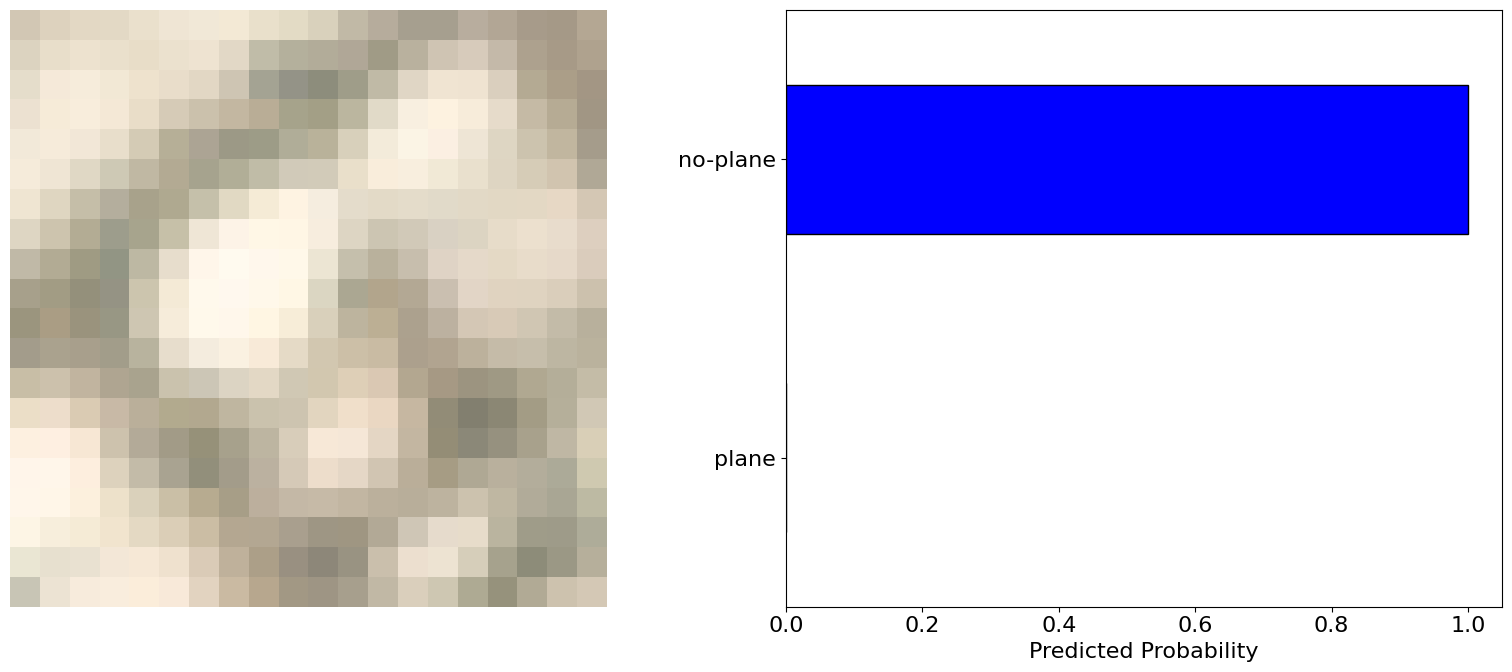

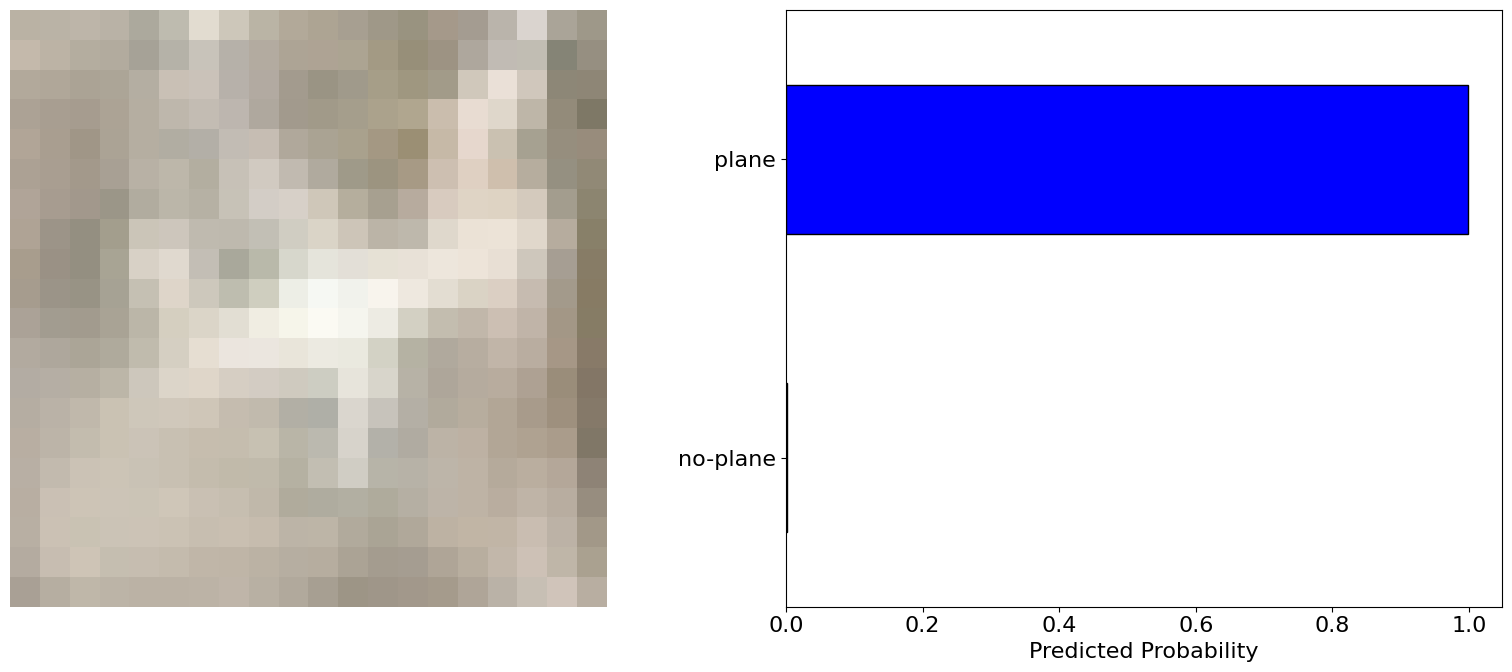

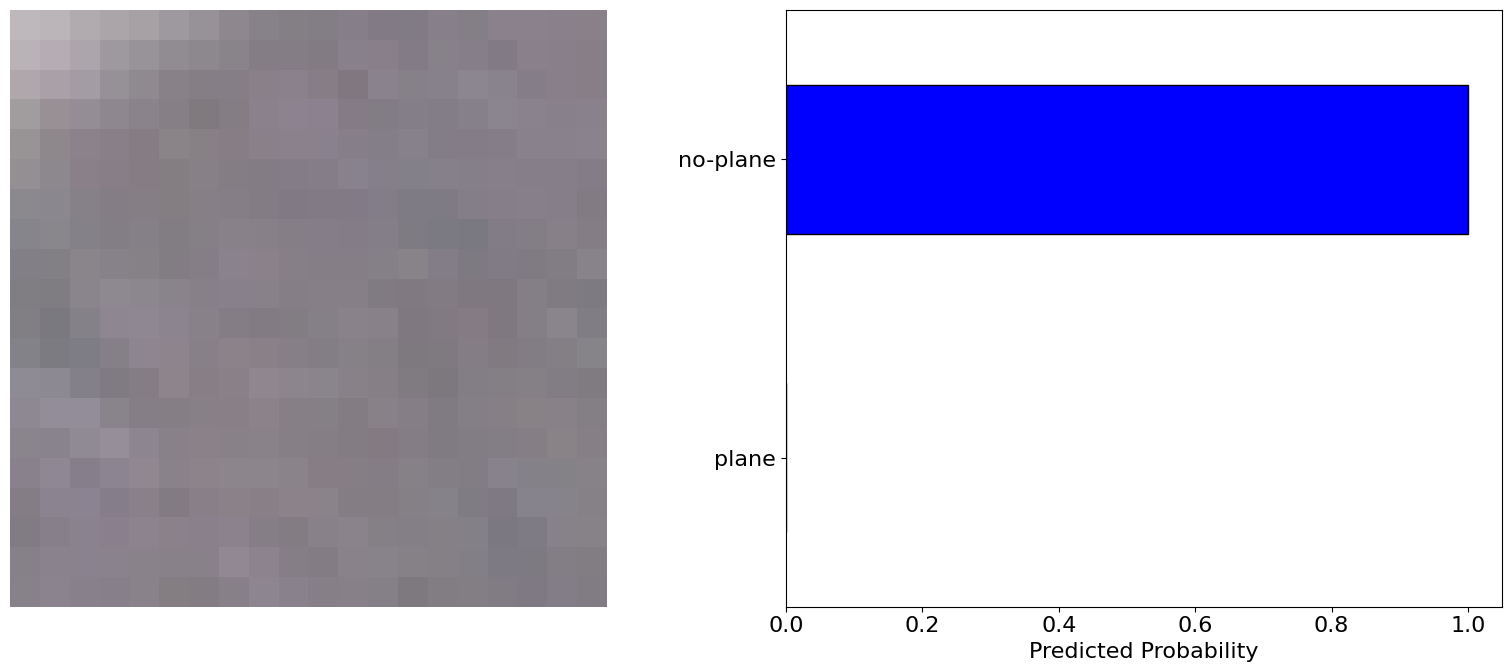

In [ ]:
labels = ["no-plane","plane"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/PlanesNet/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/planesnet/images/0__20160809_180256_0e16__-121.84811991633741_37.37283666434486.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/planesnet/images/1__20160916_174733_0e20__-118.400276531_33.94198651.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/planesnet/images/0__20151118_160424_0c68__-118.057416356_33.7872636891.png')
fig = model.predict_image(image, labels, transform)